---
title: "Van 't Riet (1979): the sulfite method as a stirred-tank gas-liquid reactor"
description: "A film coupled to a well-mixed tank, solved with pymrm for a second-order reaction: where, inside van 't Riet's own window, the sulfite method reads eq. 9's kLA without its kinetics, how wide that band of rate constants is, and whether a nil bulk does imply that the reaction runs in the boundary layer, as the review says, for each reaction order."
categories: [sec:F, struct:S1, struct:S7, tier:T1, data:tier6, phase:gas-liquid]
date: 2026-11-28
---

# Van 't Riet (1979): the sulfite method as a stirred-tank gas-liquid reactor

**Catalog ID:** `F2.6` · **Structures:** `S1` (well-mixed tank), `S7` (gas-liquid
exchange through a film) · **Tier:** T1

The sulfite method measures $k_\mathrm{L}A$ in a stirred tank by letting the
absorbed oxygen react with sodium sulfite in the liquid. The tank is then a
gas-liquid reactor, and what it reports depends on where the reaction happens:
in the bulk, in the film at the interface, or in both. Van 't Riet's 1979 review
judges the method "even more restricted" than the others because the apparent
$k_\mathrm{L}A$ must be converted with a rate constant and an order that are
hard to know. This page builds the reactor (a film coupled to the tank bulk)
and asks a narrower question with numbers: inside the review's own window of
power input and gas velocity, is there a band of rate constants in which the
method reads eq. 9's $k_\mathrm{L}A$ within the review's 20-40 % accuracy
without any conversion, how wide is that band, and does the one printed shift
of the rate constant fit inside it? For a first-order reaction the reactor has
a closed form; for the second order the review names, pymrm solves it.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "main"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "F2.6-stirred-tank-sulfite-reactor"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. The page's model.py is put on sys.path by setup().
import time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from pymrm import describe_bc
from pymrm.checks import observed_orders
from gallery_utils import (load_data, load_meta, cite_data, load_claims, Claims,
                           assert_check_values)
from model import (FilmTank, PymrmRoute, SulfiteTank, NS_LIMIT, band, closed_m1,
                   richardson, sulfite_numbers)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
T_START = time.time()
BREAK = []   # (injected defect, claim, clean value, broken value, caught)


def brk(row, metric, broken):
    """One injected defect: ``broken`` is what claim ``metric`` becomes with it."""
    caught = claims.breaks(row, metric, broken)
    BREAK.append((row, metric, claims[metric], broken, caught))

## Background

In the sulfite method a stirred vessel holds a solution of sodium sulfite with a
copper or cobalt catalyst; air or oxygen is sparged, the dissolved oxygen
oxidises sulfite to sulfate, and the oxygen transfer rate follows from the
sulfite consumed. If the oxygen in the liquid bulk is taken as zero, the
transfer rate divided by the interface concentration is an apparent
$k_\mathrm{L}A$. Van 't Riet's review (Ind. Eng. Chem. Process Des. Dev. 18,
357-364, 1979) says why that is a problem. The sentences under test are printed
from the page's statements file in the data section, verbatim from the page
images: the bulk is "nil" over a concentration range, which "implies that the
reaction largely takes place in the boundary layer", so the apparent value
"should then be converted", which needs the rate constant $k_R$ and the order;
5 % glycerin moves $k_R$ by a factor of 25 and the order runs from 1 to 2. The
abstract concludes that the method is "even more restricted".

A tank in which a dissolved gas is absorbed and consumed is a reactor with two
places for the reaction. A slow reaction runs in the bulk, the bulk is not
empty and the method under-reads. A fast reaction runs in the film, the
absorption is enhanced and the method over-reads. In between there is a band of
rate constants where neither matters to within a stated accuracy. The page
computes that band from a film model coupled to the tank (not in the review)
using only numbers the review prints, plus one assumed diffusivity, and tests
three things against the review's own window: the band's width
$W = k_\mathrm{hi}/k_\mathrm{lo}$, whether the printed 25-fold shift fits in
it, and whether a nil bulk does imply a reaction in the boundary layer.

What the page does not test: whether any published sulfite experiment sat
inside the band (no $k_R$, catalyst level, partial pressure or temperature is
printed), the ion effects on $A$ and $k_\mathrm{L}$ the review discusses, and
gas-phase depletion (page `A3.7` covers eqs. 8 and 9 and the gas column; pages
`F3.1` to `F3.3` cover film enhancement with a nil bulk). The catalogue also
lists Bakker for this entry; no Bakker source is held for the gallery and none
is used.

## The published model

### What the review prints

| id | as printed | page | used for |
| --- | --- | --- | --- |
| E1 | $\mathrm{OTR} = k_\mathrm{L}A\,(C_G/H - C_L)$, gas-side resistance neglected | eq. 1, p. 357 | interface value $C^{\ast} = C_G/H$, gas uniform |
| E9 | $k_\mathrm{L}A = 2.0\times10^{-3}\,(P/V)^{0.7}\,v_S^{0.2}$, "500 < P/V < 10,000 W/m3; 2 < V < 4400 L; strong ionic solutions; accurate for 20-40%" | eq. 9, p. 361 | $k_\mathrm{L}A$ over the window; sulfite results "are included in this section" |
| P1-P5 | the sulfite method, the nil bulk, the conversion, the glycerin factor, the orders | p. 358 | the question; $F = 25$; $m = 1, 2$ |
| P6, P7 | "1 to 2 M"; "10-100 g of sulfite/L" | pp. 359, 361 | R5 |
| P9 | $k_\mathrm{L} = 4\times10^{-4}$ used in the review; "1-4 x 10^-4" in ionic solutions | pp. 359, 361 | $k_\mathrm{L}$ at T and its floor |
| P11 | Figure 4 legend: Reith (1968) sulphite at $v_S$ 4.7 cm/s, salt 0.79 M; lines C1 at 0.45 and C2 at 4.7 cm/s | p. 361 | the $v_S$ window, T, R5 |

The review's $D$ is the stirrer diameter; it prints no diffusivity. This page
writes the oxygen diffusivity $D_m$ (code `D`). $A$ is the specific contact area
per unit liquid volume; $k_R$ is printed without a unit.

### The page's reactor model (not in the review)

Well-mixed liquid (S1); gas uniform at $C^{\ast}$; exchange through a stagnant film
of thickness $\delta = D_m/k_\mathrm{L}$ (S7); steady; sulfite in excess so the
rate is $k_m c^m$ (pseudo-$m$-th order). With $\xi = x/\delta$ and $u = c/C^{\ast}$:

$$u'' = \mathrm{Ha}^2 u^m,\qquad u(0) = 1,\qquad u(1) = u_b,\qquad
  g \equiv -u'(1) = \mathrm{Ha}^2(\mathrm{Al} - 1)\,u_b^m$$

$$\mathrm{Ha}^2 = \frac{k_m C^{\ast\,m-1} D_m}{k_\mathrm{L}^2},\qquad
  \mathrm{Al} = \frac{k_\mathrm{L}}{A D_m} = \frac{k_\mathrm{L}^2}{D_m\,k_\mathrm{L}A}$$

The last equation is the bulk balance per unit liquid volume: what leaves the
film reacts in the bulk volume outside the films, $1 - A\delta = 1 - 1/\mathrm{Al}$.
The method's reading relative to the true $k_\mathrm{L}A$ is
$\varphi = -u'(0) = \mathrm{OTR}/(k_\mathrm{L}A\,C^{\ast})$; the enhancement is
$E = \varphi/(1-u_b)$; the film's share of the reaction is $f = 1 - g/\varphi$; and
the oxygen balance is $\varphi = g + \mathrm{Ha}^2\int_0^1 u^m\,d\xi$. The band is
$1 - \mathrm{tol} \le \varphi \le 1 + \mathrm{tol}$; its edges
$\mathrm{Ha}^2_\mathrm{lo}$ and $\mathrm{Ha}^2_\mathrm{hi}$ are roots, and since
$\mathrm{Ha}^2 \propto k_m$ at fixed conditions,
$W = \mathrm{Ha}^2_\mathrm{hi}/\mathrm{Ha}^2_\mathrm{lo} = k_\mathrm{hi}/k_\mathrm{lo}$
needs no value of $k_R$, $C^{\ast}$ or the catalyst level, and does not depend on how
$\mathrm{Ha}$ is normalised (the factor $2/(m+1)$ of the Hikita-Asai form cancels).
The one group that sets $W$ is $\mathrm{Al}$, from eq. 9, $k_\mathrm{L}$ and $D_m$.

| symbol | code | meaning |
| --- | --- | --- |
| $\mathrm{Ha}^2$ | `Ha2` | reaction against film diffusion |
| $\mathrm{Al}$ | `Al` | liquid volume per film volume (Hinterland ratio) |
| $u_b$ | `ub` | bulk oxygen relative to $C^{\ast}$ |
| $\varphi$ | `phi` | method reading / true $k_\mathrm{L}A$ |
| $f$ | `film_share` | share of the reaction in the film |
| $W$ | `W` | band width $k_\mathrm{hi}/k_\mathrm{lo}$ |

For $m = 1$ the solution is closed:
$u_b = 1/(\cosh\mathrm{Ha} + \mathrm{Ha}(\mathrm{Al}-1)\sinh\mathrm{Ha})$,
$\varphi = (\mathrm{Ha}/\tanh\mathrm{Ha})(1 - u_b/\cosh\mathrm{Ha})$. For $m = 2$
there is no elementary closed form: pymrm solves it.

## Parameters and assumptions

Every constant is read from a CSV in the next cell: eq. 9, $k_\mathrm{L}$, the
accuracy and the Figure 4 legend from page `A3.7`'s files, the sulfite statements
from this page's file. Assumed, and marked wherever they enter:

- $D_m$ (not printed): it enters only through $\mathrm{Al}$, so instead of
  sweeping an invented range the page prints the $D_m$ at which each box verdict
  flips (R4);
- $A$ per unit liquid volume (per dispersion volume multiplies $\mathrm{Al}$ by
  $1 - \varepsilon$, which is the same as $D_m/(1-\varepsilon)$: the same flip
  table applies, and no holdup value is invented);
- film theory (surface renewal is a sensitivity of the upper edge, R4);
- the test condition T: the log-centre of eq. 9's $P/V$ range, and Figure 4's
  Reith sulphite line $v_S$ = 4.7 cm/s, at the review's $k_\mathrm{L}$;
- for R5 only: the molar mass of $\mathrm{Na_2SO_3}$ (external), and for the
  instantaneous-reaction bound $C^{\ast}$ and the sulfite-to-oxygen diffusivity ratio.

In [3]:
A37 = "A3.7-vant-riet-kla"
corr = load_data("vant-riet-1979-correlations.csv", page=A37)
nums = load_data("vant-riet-1979-printed-numbers.csv", page=A37).set_index("key")
legs = load_data("vant-riet-1979-figure-legends.csv", page=A37, dtype=str)
stm = load_data("vant-riet-1979-sulfite-statements.csv", page=PAGE, dtype=str).set_index("key")
eq9 = corr[corr.equation == 9].iloc[0]
f4 = legs[legs.figure == "4"]
reith = f4[f4.author == "Reith"].iloc[0]
c_lines = f4[f4.method == "drawn correlation line"].set_index("entry")
f5_ionic = legs[(legs.figure == "5") & (legs.liquid == "ionic")]

D_ASSUMED = 2.0e-9     # m2/s, O2 diffusivity in the sulfite solution: ASSUMED, not printed
P0 = dict(
    K=float(eq9.K), alpha=float(eq9.alpha), beta=float(eq9.beta),  # eq. 9 (A3.7 CSV)
    vs_unit=1.0,                                                    # v_s in m/s
    kL=float(nums.loc["kL_used_in_review", "value"]),               # m/s, p. 359
    D=D_ASSUMED,
    pv_T=float(np.sqrt(eq9.pv_min_W_m3 * eq9.pv_max_W_m3)),         # W/m3, log-centre
    vs_T=float(reith.vs_m_s),                                       # m/s, Figure 4 Reith
    pv_box=(float(eq9.pv_min_W_m3), float(eq9.pv_max_W_m3)),        # W/m3, eq. 9
    vs_box=(float(c_lines.loc["C1", "vs_m_s"]), float(c_lines.loc["C2", "vs_m_s"])),  # m/s
    F=float(stm.loc["kR_shift_factor", "value"]),                   # the printed k_R shift
)
TOLS = (float(nums.loc["accuracy_lo_pct", "value"]) / 100,
        float(nums.loc["accuracy_hi_pct", "value"]) / 100)         # eq. 9's 20-40 %
ORD = (int(stm.loc["order_at_1atm", "value"]), int(stm.loc["order_at_low_pO2", "value"]))
KL_FLOOR = float(nums.loc["kL_ionic_lo", "value"])                  # m/s, p. 361
KL_PURE_TOP = float(nums.loc["kL_literature_hi", "value"])          # m/s, pure water, p. 359
VS_FIG5 = (float(f5_ionic.vs_m_s.astype(float).min()), float(f5_ionic.vs_m_s.astype(float).max()))
SULF = dict(
    M=126.04,        # g/mol, Na2SO3 from standard atomic weights (external)
    g_lo=float(stm.loc["sulfite_lo", "value"]), g_hi=float(stm.loc["sulfite_hi", "value"]),
    ion_factor=3.0,  # ionic strength per mol Na2SO3: (2 x 1^2 + 1 x 2^2)/2
    C_star=1.2,      # mol/m3, ASSUMED (about pure O2 at 1 atm), only in the E_inf bound
    DB_over_D=0.5,   # ASSUMED sulfite/O2 diffusivity ratio, only in the E_inf bound
    nu=2.0,          # mol sulfite per mol O2 (2 SO3^2- + O2 -> 2 SO4^2-)
)
for k, v in {**P0, "tol": TOLS, "orders": ORD, "kL_floor": KL_FLOOR}.items():
    print(f"  {k:9s} {v}")

  K         0.002
  alpha     0.7
  beta      0.2
  vs_unit   1.0
  kL        0.0004
  D         2e-09
  pv_T      2236.06797749979
  vs_T      0.047
  pv_box    (500.0, 10000.0)
  vs_box    (0.0045, 0.047)
  F         25.0
  tol       (0.2, 0.4)
  orders    (1, 2)
  kL_floor  0.0001


## The data

Nothing on this page is measured: there is no figure to digitise for the sulfite
reactor (the review's Figure 4 shows Reith and Beek's areas converted with
$k_\mathrm{L}$, not reactor readings). The page uses two kinds of rows.

| file | page | what it is |
| --- | --- | --- |
| `vant-riet-1979-correlations.csv` | `A3.7` | eq. 9's constants, window and accuracy |
| `vant-riet-1979-printed-numbers.csv` | `A3.7` | $k_\mathrm{L}$ values and the 20-40 % accuracy |
| `vant-riet-1979-figure-legends.csv` | `A3.7` | the Figure 4 legend (typeset text, not curve data) |
| `vant-riet-1979-sulfite-statements.csv` | this page | the sulfite sentences, verbatim, with page numbers |

What page `A3.7` established about the rows used here, and whether it matters:

1. Eqs. 8 and 9 were read at the scan's native 300 ppi from crops; the text layer
   does not render either equation. Not an issue here: the same CSV is loaded.
2. The legends of Figures 1-4 cite an equation number one lower than the text
   (Figure 4's lines say "equation (8)" for eq. 9). Not used: only the $v_S$ and
   salt columns are read.
3. Eq. 9's $v_S^{0.2}$ is not resolved by the data: with the prefactor refitted,
   deleting it costs less than the review's accuracy (the value is printed below
   from A3.7's claims). This matters: $\mathrm{Al} \propto v_S^{-0.2}$, so the
   $v_S$ direction of the box rests on that exponent. The page keeps eq. 9 as
   printed and does not refit it.
4. Eq. 2's gassing-out readings, the source of most of eq. 9's data, are biased
   low on the ionic branch at the window centre (value below, from A3.7). Eq. 9
   as fitted contains whatever bias its data had; a $k_\mathrm{L}A$ higher than
   eq. 9 lowers $\mathrm{Al}$. The page takes eq. 9 at face value and says so.
5. The "1-4 x 10^-4" sentence is garbled ("a factor in excess of 1-4"); A3.7
   did not use those rows. This page uses only the range, $10^{-4}$ as the
   floor of $k_\mathrm{L}$.

In [4]:
a37 = load_claims(A37)
print("A3.7: cost of deleting eq. 9's v_s^0.2 over Figure 4's lines "
      f"{100 * a37['null_ion_beta0_cost']:.1f} % (the review's accuracy: "
      f"{100 * TOLS[0]:.0f}-{100 * TOLS[1]:.0f} %)")
print(f"A3.7: eq. 2 bias on the ionic branch at the window centre {100 * a37['bias_ionic_transient']:.1f} %")
print()
for key in ("method_reaction", "nil_bulk_boundary_layer", "conversion_needs_kinetics",
            "glycerin_pct", "order_at_1atm", "ionic_conc_lo", "sulfite_lo",
            "reith_beek_most_reliable", "abstract_more_restricted"):
    r = stm.loc[key]
    print(f"p. {r.journal_page} [{key}]: \"{r.statement}\"")
print()
print(cite_data(load_meta("vant-riet-1979-sulfite-statements.csv", page=PAGE)))

A3.7: cost of deleting eq. 9's v_s^0.2 over Figure 4's lines 26.4 % (the review's accuracy: 20-40 %)
A3.7: eq. 2 bias on the ionic branch at the window centre 45.4 %

p. 358 [method_reaction]: "This method is based on the reaction of absorbed O2 with Na2SO3. Copper and cobalt ions can be used as catalyst."
p. 358 [nil_bulk_boundary_layer]: "Mostly, there is a concentration range in which the reaction proceeds so rapidly that the dissolved oxygen concentration in the liquid is nil. This implies that the reaction largely takes place in the boundary layer and that the driving force is larger than if there were only physically controlled absorption. The apparent kLA thus determined should then be converted into the kLA for that absorption."
p. 358 [conversion_needs_kinetics]: "The conversion makes it necessary to determine both the reaction rate constant kR and the order of the reaction, and, as appears from the literature, problems arise here."
p. 358 [glycerin_pct]: "Onken and Schalk (19

## PyMRM implementation

`model.py` holds the reactor. `FilmTank` discretises the film on $n$ finite
volumes with `construct_grad` and `construct_div` (`nu = 0`, a flat film),
assembled once. The interface face carries $u(0) = 1$ as a constant
boundary vector. The bulk face carries $u(1) = u_b$ through `shapes_d`: the
dictionary's `d = 1` is the coefficient of an external unknown, so the gradient
operator stays constant while $u_b$ changes. The unknowns are
$[u_1, \dots, u_n, u_b]$, a bordered system: the film rows
$\mathrm{div}(\mathrm{grad}\,u) - \mathrm{Ha}^2 u^m$, with $u_b$ entering through
`div @ grad_bc_right`, and one bulk row $g - \mathrm{Ha}^2(\mathrm{Al}-1)u_b^m$, with
$g$ the operator's last face gradient. The Jacobian is analytic, assembled with
`block_array` in CSC, and `newton` solves it (`tol` 1e-10, above the round-off
floor; `success` is checked in every solve). $\varphi$ and $g$ are read from the
gradient operator's face values with the boundary vectors included, never from a
cell.

`SulfiteTank` holds every constant in one dictionary and evaluates each result on
a route: the closed form for $m = 1$ (exact), and for $m = 2$ the pymrm solution on
200, 400 and 800 cells, combined by Richardson extrapolation that removes the
$h^2$ and $h^3$ terms of the finite-volume error (the one-sided Dirichlet face
gradients add the odd term). Band edges, nil points and $\mathrm{Al}_{25}$ are
roots by `pymrm.checks.find_roots` (log scan, exactly one root or the page stops),
taken on each level and then extrapolated.

In [5]:
tank = FilmTank(8)
bc_shown = ({"a": 0.0, "b": 1.0, "d": 1.0}, {"a": 0.0, "b": 1.0, "d": 1.0})
print(describe_bc(bc_shown, tank.x_f))
st0 = SulfiteTank(P0)
COND = st0.conditions()
AL_T = COND["Al_T"]
demo = FilmTank(400).solve(1.0, AL_T, 2)
print(f"\nT, Ha^2 = 1, m = 2 on 400 cells: phi = {demo['phi']:.6f}, u_b = {demo['ub']:.6f}, "
      f"newton iterations {demo['nit']}, O2 balance below 1e-11 (here {abs(demo['balance']):.0e})")

lower (x=0, outward normal -x): 0*dc/dx + 1*c = 1  [Dirichlet]
upper (x=1, outward normal +x): 0*dc/dx + 1*c = 1  [Dirichlet]

T, Ha^2 = 1, m = 2 on 400 cells: phi = 1.190432, u_b = 0.051050, newton iterations 9, O2 balance below 1e-11 (here 4e-12)


In [6]:
def tg(m, tol):
    """Label of an (order, tolerance) case."""
    return f"m{m}_tol{round(100 * tol)}"


def ktag(kl):
    return f"{kl:.0e}".replace("e-0", "e-")


KT, KLO = ktag(P0["kL"]), ktag(KL_FLOOR)


def pack(names, val_err):
    """Values and grid errors of one evaluation under the given claim names."""
    v, e = val_err
    return dict(zip(names, np.atleast_1d(v).tolist())), dict(zip(names, np.atleast_1d(e).tolist()))


def g_cond(st):
    c = st.conditions()
    return {"kla_T": c["kla_T"], "Al_T": c["Al_T"], "box_kla_min": c["kla_min"],
            "box_kla_max": c["kla_max"], f"box_kL{KT}_Al_min": c["Al_min"],
            f"box_kL{KT}_Al_max": c["Al_max"]}, {}


def g_point(st, m, me=None):
    """phi, u_b, g, film share and E at T, Ha^2 = 1 (``me``: the order computed)."""
    return pack([f"m{m}_Ha2_1_{k}" for k in ("phi", "ub", "film_share", "E", "g")],
                st.point(me or m))


def g_band(st, m, tol, me=None, te=None):
    """The band at T (``me``, ``te``: the order and tolerance computed)."""
    return pack([f"{tg(m, tol)}_{k}_T" for k in ("Ha2_lo", "Ha2_hi", "W")],
                st.band(me or m, te or tol))


def g_lim(st, m, tol, me=None, Al=None, te=None):
    """The film-alone upper edge, the slope of W in Al, and for m = 1 the surface
    renewal edge and its ratio to the film's."""
    t = tg(m, tol)                   # the label is the case's; te is what is computed
    me, tol = me or m, te or tol
    (hE,), (eE,) = st.film_limit(me, tol, Al=Al)
    out = {f"lim_{t}_Ha2_E": hE, f"lim_{t}_W_slope": hE / ((1 - tol) / tol ** me)}
    err = {f"lim_{t}_Ha2_E": eE, f"lim_{t}_W_slope": eE / ((1 - tol) / tol ** me)}
    if m == 1:
        sr = (1 + tol) ** 2 - 1    # surface renewal, phi = sqrt(1 + Ha^2), u_b -> 0
        out.update({f"lim_{t}_Ha2_E_surface_renewal": sr,
                    f"lim_{t}_upper_edge_ratio_sr_over_film": sr / hE})
    return out, err


def g_box(st, m, tol, me=None, alF=None):
    """Al_25, W at the box corners, the share with W >= F, margins and the D flips,
    at the review's k_L and at its ionic floor. ``alF`` reuses a root that the
    defect does not touch (eq. 9, k_L and the box do not enter Al_25)."""
    me = me or m
    t = tg(m, tol)
    if alF is None:
        (alF,), (eA,) = st.al_F(me, tol)
    else:
        eA = 0.0
    b4, b1 = st.box(me, tol, al_F=alF), st.box(me, tol, kL=KL_FLOOR, al_F=alF)
    out = {f"box_{t}_Al_25": alF, f"box_{t}_kL{KT}_W_min": b4["W_min"],
           f"box_{t}_kL{KT}_W_max": b4["W_max"], f"box_{t}_kL{KLO}_W_min": b1["W_min"],
           f"box_{t}_kL{KLO}_W_max": b1["W_max"], f"box_{t}_kL{KT}_D_all_W_ge_25": b4["D_all"],
           f"box_{t}_kL{KT}_D_none_W_ge_25": b4["D_none"],
           f"box_{t}_kL{KT}_margin_Almin_over_Al25": b4["margin_min"]}
    if tol == TOLS[0]:
        # the T verdict reverses where Al_T meets Al_25: Al goes as k_L^2/(D k_L A)
        aT = st.conditions()["Al_T"]
        out[f"{t}_D_flip_T"] = st.P["D"] * aT / alF
        out[f"{t}_kL_flip_T"] = st.P["kL"] * np.sqrt(alF / aT)
        out.update({f"box_{t}_kL{KT}_frac_W_ge_25": b4["share"],
                    f"box_{t}_kL{KLO}_margin_Almax_over_Al25": b1["margin_max"]})
    else:
        out[f"box_{t}_kL{KLO}_frac_W_ge_25"] = b1["share"]
    return out, {f"box_{t}_Al_25": eA}


def g_nil(st, m, me=None):
    """Where the bulk is nil to 1 %, 5 % and (first order) 0.1 %, where the film carries half the
    reaction (at T), and the film share at the nil point at both Al corners."""
    me = me or m
    out, err = {}, {}
    for tgt, nm in ((0.01, "nil01"), (0.05, "nil05"), (0.001, "nil0p1")):
        if nm == "nil0p1" and m != 1:
            continue    # the second order's three-level limit is too coarse at 0.1 %
        v, e = st.where(me, "ub", tgt)
        for i, k in ((0, "Ha2"), (3, "film_share"), (1, "phi")):
            out[f"m{m}_{nm}_{k}_T"], err[f"m{m}_{nm}_{k}_T"] = v[i], e[i]
    v, e = st.where(me, "film_share", 0.5)
    for i, k in ((0, "Ha2"), (1, "phi"), (2, "ub")):
        out[f"m{m}_film50_{k}_T"], err[f"m{m}_film50_{k}_T"] = v[i], e[i]
    c = st.conditions()
    for corner in ("min", "max"):
        v, e = st.where(me, "ub", 0.01, Al=c[f"Al_{corner}"])
        out[f"box_m{m}_nil01_film_share_at_Al_{corner}"] = v[3]
        err[f"box_m{m}_nil01_film_share_at_Al_{corner}"] = e[3]
    return out, err


def g_nilflip(st, m, me=None, al_flip=None, root=True):
    """The Al below (m = 1) or above (m = 2) which the nil-bulk verdict flips, the
    diffusivity at which the box's corner crosses it, and the film share at the nil
    point at the two corners of the box at the k_L floor. ``al_flip`` reuses the
    root when the defect does not reach it (eq. 9, k_L and the box do not)."""
    me = me or m
    out, e = {}, 0.0
    if root:
        if al_flip is None:
            (al_flip,), (e,) = st.nil_flip(me)
        c = st.conditions()
        corner = c["Al_min"] if m == 1 else c["Al_max"]
        out = {f"nil_flip_Al_m{m}": al_flip, f"nil_flip_D_m{m}": st.P["D"] * corner / al_flip}
    cf = st.conditions(kL=KL_FLOOR)
    for k in ("min", "max"):
        out[f"box_m{m}_nil01_film_share_at_kL{KLO}_Al_{k}"] = st.where(
            me, "ub", 0.01, Al=cf[f"Al_{k}"])[0][3]
    return out, ({f"nil_flip_Al_m{m}": e} if root else {})


def g_r5(c, salt_printed):
    """The printed sulfite numbers: molarity and ionic strength at 10 and 100 g/L, the
    0.79 M of Figure 4 in half-units of its last digit, the two readings of '1 to 2 M',
    and the instantaneous-reaction bound at 10 g/L."""
    s = sulfite_numbers(c)
    half = 0.5 * 10.0 ** -len(salt_printed.split(".")[1])
    lo_M, hi_M = float(stm.loc["ionic_conc_lo", "value"]), float(stm.loc["ionic_conc_hi", "value"])
    return {"printed_na2so3_molar_10gL": s["molar_lo"], "printed_na2so3_molar_100gL": s["molar_hi"],
            "printed_ionic_strength_10gL": s["ionic_lo"],
            "printed_ionic_strength_100gL": s["ionic_hi"],
            "salt_079_half_units": abs(s["molar_hi"] - float(salt_printed)) / half,
            "reading_salt_gap_to_1M": lo_M - s["molar_hi"],
            "reading_ionic_cover_margin": min(lo_M - s["ionic_lo"], s["ionic_hi"] - hi_M),
            "E_inf_10gL": s["E_inf_10gL"]}, {}

## Results

### R1. The reactor at the test condition

The method's reading $\varphi$ against $\mathrm{Ha}^2$ (proportional to the rate
constant) at T, for both orders. At small $\mathrm{Ha}^2$ the bulk is not empty and
$\varphi < 1$; at large $\mathrm{Ha}^2$ the film enhances the absorption and
$\varphi > 1$; the band where $|\varphi - 1| \le \mathrm{tol}$ lies between. The
curves for $m = 2$ are plotted from 200 cells; every number quoted is a
three-level limit.

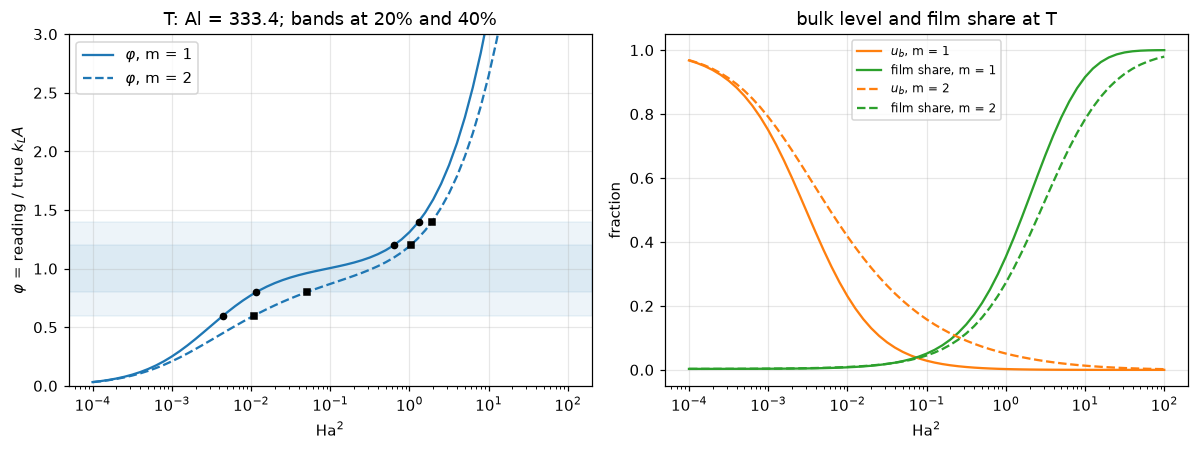

In [7]:
VAL, ERR = {}, {}


def collect(res):
    VAL.update(res[0]); ERR.update(res[1])


collect(g_cond(st0))
for m in ORD:
    collect(g_point(st0, m))
    for tol in TOLS:
        collect(g_band(st0, m, tol))
        collect(g_lim(st0, m, tol))

H2 = np.geomspace(1e-4, 1e2, 61)
r200 = PymrmRoute(200)
curves = {1: [closed_m1(h, AL_T) for h in H2], 2: [r200(h, AL_T, 2) for h in H2]}
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for m, ls in zip(ORD, ("-", "--")):
    ax[0].semilogx(H2, [s["phi"] for s in curves[m]], ls, color="C0", label=f"$\\varphi$, m = {m}")
    ax[1].semilogx(H2, [s["ub"] for s in curves[m]], ls, color="C1", label=f"$u_b$, m = {m}")
    ax[1].semilogx(H2, [s["film_share"] for s in curves[m]], ls, color="C2",
                   label=f"film share, m = {m}")
    for tol in TOLS:
        for side in ("lo", "hi"):
            ax[0].plot(VAL[f"{tg(m, tol)}_Ha2_{side}_T"], 1 + (tol if side == "hi" else -tol),
                       "o" if m == 1 else "s", color="k", ms=4)
for tol in TOLS:
    ax[0].axhspan(1 - tol, 1 + tol, color="C0", alpha=0.08)
ax[0].set(xlabel="Ha$^2$", ylabel="$\\varphi$ = reading / true $k_LA$", ylim=(0, 3),
          title=f"T: Al = {AL_T:.1f}; bands at {TOLS[0]:.0%} and {TOLS[1]:.0%}")
ax[1].set(xlabel="Ha$^2$", ylabel="fraction", title="bulk level and film share at T")
ax[0].legend(); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
rows = [f"| order | Ha² = 1: φ | u_b | film share | E |", "| --- | --- | --- | --- | --- |"]
for m in ORD:
    rows.append(f"| {m} | {VAL[f'm{m}_Ha2_1_phi']:.5f} | {VAL[f'm{m}_Ha2_1_ub']:.5f} | "
                f"{VAL[f'm{m}_Ha2_1_film_share']:.4f} | {VAL[f'm{m}_Ha2_1_E']:.5f} |")
display(Markdown(
    f"At T, eq. 9 gives $k_\\mathrm{{L}}A$ = {VAL['kla_T']:.4f} 1/s and "
    f"$\\mathrm{{Al}}$ = {AL_T:.1f} (with the assumed $D_m$). At $\\mathrm{{Ha}}^2 = 1$ "
    "both orders already read above the true value, with the film's share of the "
    "reaction as listed:\n\n" + "\n".join(rows)))

At T, eq. 9 gives $k_\mathrm{L}A$ = 0.2399 1/s and $\mathrm{Al}$ = 333.4 (with the assumed $D_m$). At $\mathrm{Ha}^2 = 1$ both orders already read above the true value, with the film's share of the reaction as listed:

| order | Ha² = 1: φ | u_b | film share | E |
| --- | --- | --- | --- | --- |
| 1 | 1.31087 | 0.00255 | 0.3534 | 1.31422 |
| 2 | 1.19043 | 0.05105 | 0.2722 | 1.25447 |

### R2. The band, and whether the printed 25-fold shift fits in it

The band at T for each order and tolerance, then over the box: $W$ rises
monotonically with $\mathrm{Al}$ (the scan below, on 200 cells for $m = 2$; the page
raises if any case is not monotone), so $W \ge 25$ wherever
$\mathrm{Al} \ge \mathrm{Al}_{25}$, a root, and in the box that is the half-plane
$0.7\ln(P/V) + 0.2\ln v_S \le \ln\!\big(k_\mathrm{L}^2/(D_m\,\mathrm{Al}_{25}\,K)\big)$.
Its share of the box is measured as a log-area (eq. 9 is a power law, and the
box is read on log axes), integrated exactly.

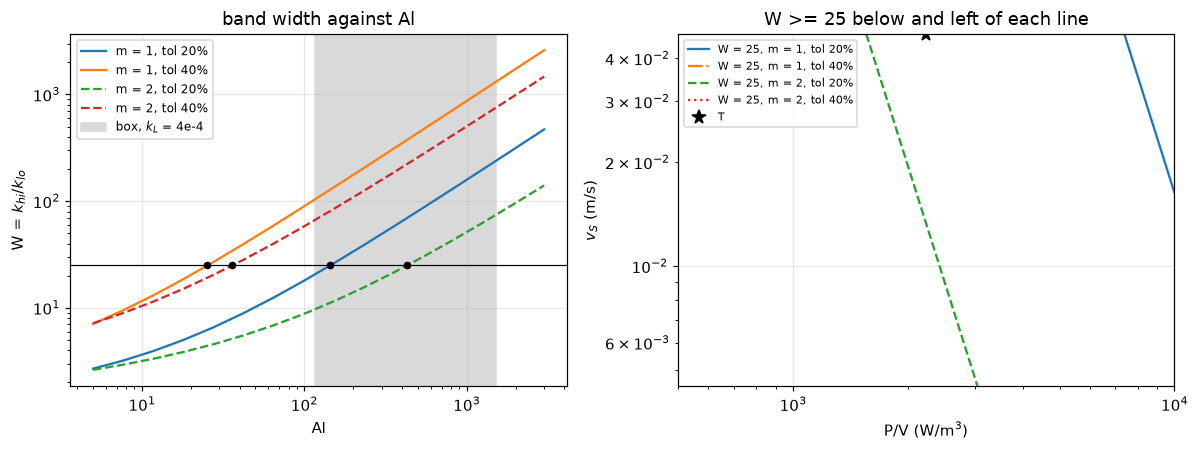

In [9]:
for m in ORD:
    for tol in TOLS:
        collect(g_box(st0, m, tol))

AL_SCAN = np.geomspace(5.0, 3000.0, 16)
scan = {}
for m in ORD:
    solver = (lambda h, a, mm: closed_m1(h, a)) if m == 1 else PymrmRoute(200)
    for tol in TOLS:
        scan[(m, tol)] = np.array([band(solver, a, m, tol)[2] for a in AL_SCAN])
        if not np.all(np.diff(scan[(m, tol)]) > 0):
            raise RuntimeError(f"W(Al) is not monotone for m = {m}, tol = {tol}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
for (m, tol), w in scan.items():
    ax[0].loglog(AL_SCAN, w, "-" if m == 1 else "--", label=f"m = {m}, tol {tol:.0%}")
    ax[0].plot(VAL[f"box_{tg(m, tol)}_Al_25"], P0["F"], "ko", ms=4)
ax[0].axvspan(COND["Al_min"], COND["Al_max"], color="0.85", label="box, $k_L$ = 4e-4")
ax[0].axhline(P0["F"], color="k", lw=0.8)
ax[0].set(xlabel="Al", ylabel="W = $k_{hi}/k_{lo}$", title="band width against Al")
ax[0].legend(fontsize=8)
pv = np.geomspace(*P0["pv_box"], 50)
for (m, tol), ls in zip([(m, t) for m in ORD for t in TOLS], ("-", "-.", "--", ":")):
    cc = np.log(P0["kL"] ** 2 / (P0["D"] * VAL[f"box_{tg(m, tol)}_Al_25"] * P0["K"]))
    ax[1].loglog(pv, np.exp((cc - P0["alpha"] * np.log(pv)) / P0["beta"]), ls,
                 label=f"W = 25, m = {m}, tol {tol:.0%}")
ax[1].set(xlim=P0["pv_box"], ylim=P0["vs_box"], xlabel="P/V (W/m$^3$)", ylabel="$v_S$ (m/s)",
          title="W >= 25 below and left of each line")
ax[1].plot(P0["pv_T"], P0["vs_T"], "k*", ms=9, label="T")
ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [10]:
rows = ["| case | Ha²_lo at T | Ha²_hi at T | W at T | Al₂₅ | W over the box | share with W ≥ 25 |",
        "| --- | --- | --- | --- | --- | --- | --- |"]
for m in ORD:
    for tol in TOLS:
        t = tg(m, tol)
        share = (VAL[f"box_{t}_kL{KT}_frac_W_ge_25"] if tol == TOLS[0] else 1.0
                 if VAL[f"box_{t}_kL{KT}_margin_Almin_over_Al25"] > 1 else float("nan"))
        rows.append(f"| m = {m}, {tol:.0%} | {VAL[f'{t}_Ha2_lo_T']:.5f} | {VAL[f'{t}_Ha2_hi_T']:.4f} | "
                    f"{VAL[f'{t}_W_T']:.1f} | {VAL[f'box_{t}_Al_25']:.1f} | "
                    f"{VAL[f'box_{t}_kL{KT}_W_min']:.1f} to {VAL[f'box_{t}_kL{KT}_W_max']:.1f} | "
                    f"{share:.4f} |")
FIT_T = [VAL[f"{tg(m, t)}_W_T"] for m in ORD for t in TOLS]
FIT_BOX = [VAL[f"box_{tg(m, t)}_kL{KT}_margin_Almin_over_Al25"] for m in ORD for t in TOLS]
display(Markdown(
    "\n".join(rows) + "\n\n"
    f"At T the printed shift of {P0['F']:.0f} fits inside the band in "
    f"{sum(w >= P0['F'] for w in FIT_T)} of {len(FIT_T)} cases; over the whole box, in "
    f"{sum(x >= 1 for x in FIT_BOX)} of {len(FIT_BOX)} (both at {TOLS[1]:.0%}, where "
    f"$\\mathrm{{Al}}_{{\\min}}/\\mathrm{{Al}}_{{25}}$ = "
    f"{VAL[f'box_{tg(1, TOLS[1])}_kL{KT}_margin_Almin_over_Al25']:.2f} and "
    f"{VAL[f'box_{tg(2, TOLS[1])}_kL{KT}_margin_Almin_over_Al25']:.2f}). At {TOLS[0]:.0%} it fits on "
    f"{VAL[f'box_{tg(1, TOLS[0])}_kL{KT}_frac_W_ge_25']:.3f} of the box for $m = 1$ and on "
    f"{VAL[f'box_{tg(2, TOLS[0])}_kL{KT}_frac_W_ge_25']:.3f} for $m = 2$; the part that misses is "
    "the high-power, high-gas-rate corner, where $k_\\mathrm{L}A$ is largest and "
    "$\\mathrm{Al}$ smallest."))

| case | Ha²_lo at T | Ha²_hi at T | W at T | Al₂₅ | W over the box | share with W ≥ 25 |
| --- | --- | --- | --- | --- | --- | --- |
| m = 1, 20% | 0.01168 | 0.6369 | 54.5 | 144.4 | 20.7 to 240.0 | 0.9772 |
| m = 1, 40% | 0.00447 | 1.3057 | 292.2 | 25.3 | 104.4 to 1321.7 | 1.0000 |
| m = 2, 20% | 0.05084 | 1.0386 | 20.4 | 429.7 | 9.7 to 74.8 | 0.4909 |
| m = 2, 40% | 0.01097 | 1.9232 | 175.3 | 36.1 | 66.8 to 756.1 | 1.0000 |

At T the printed shift of 25 fits inside the band in 3 of 4 cases; over the whole box, in 2 of 4 (both at 40%, where $\mathrm{Al}_{\min}/\mathrm{Al}_{25}$ = 4.61 and 3.24). At 20% it fits on 0.977 of the box for $m = 1$ and on 0.491 for $m = 2$; the part that misses is the high-power, high-gas-rate corner, where $k_\mathrm{L}A$ is largest and $\mathrm{Al}$ smallest.

### R3. Does a nil bulk imply a reaction in the boundary layer?

The review's sentence, tested per order: find the rate constant at which the bulk
is nil to 1 % ($u_b$ = 0.01; 5 % as a sensitivity), and read the film's share of
the reaction there. "Largely in the boundary layer" is read as a film share above
one half. The rate constant at which the film carries exactly half is a second
root, and the method's reading there says whether that point is still inside the
band.

In [11]:
for m in ORD:
    collect(g_nil(st0, m))
    collect(g_nilflip(st0, m))

rows = ["| order | Ha² at u_b = 0.01 | film share there | φ there | film share, Al_min / Al_max | "
        "Ha² at film share ½ | φ there |", "| --- | --- | --- | --- | --- | --- | --- |"]
for m in ORD:
    rows.append(f"| {m} | {VAL[f'm{m}_nil01_Ha2_T']:.4f} | {VAL[f'm{m}_nil01_film_share_T']:.4f} | "
                f"{VAL[f'm{m}_nil01_phi_T']:.4f} | "
                f"{VAL[f'box_m{m}_nil01_film_share_at_Al_min']:.4f} / "
                f"{VAL[f'box_m{m}_nil01_film_share_at_Al_max']:.4f} | "
                f"{VAL[f'm{m}_film50_Ha2_T']:.4f} | {VAL[f'm{m}_film50_phi_T']:.4f} |")
NIL = {m: [VAL[f"box_m{m}_nil01_film_share_at_Al_{c}"] for c in ("min", "max")] for m in ORD}
NIL_FLOOR = {m: [VAL[f"box_m{m}_nil01_film_share_at_kL{KLO}_Al_{c}"] for c in ("min", "max")]
             for m in ORD}
display(Markdown(
    "\n".join(rows) + "\n\n"
    f"For $m = 1$ the film carries more than half of the reaction at the nil point at "
    f"{sum(f > 0.5 for f in NIL[1])} of 2 box corners: where the bulk is nil, most of the "
    f"reaction still runs in the bulk, which is large ($\\mathrm{{Al}}$ from {COND['Al_min']:.0f} "
    f"to {COND['Al_max']:.0f} over the box) and needs only a trace of oxygen to consume what "
    "the film passes. At 1 % the implication fails. "
    f"For $m = 2$ it holds at {sum(f > 0.5 for f in NIL[2])} of 2: a second-order rate "
    "collapses as $u_b^2$, so a nil bulk needs a fast reaction, which runs in the film. "
    f"The verdict is the 1 % reading of nil, not the order alone: at T the film carries half "
    f"once the bulk falls below $u_b$ = {VAL['m1_film50_ub_T']:.4g} ($m = 1$) and "
    f"{VAL['m2_film50_ub_T']:.4g} ($m = 2$); at $u_b$ = 0.1 % the first-order film share at T "
    f"is {VAL['m1_nil0p1_film_share_T']:.3f}, and at 5 % the second-order share is "
    f"{VAL['m2_nil05_film_share_T']:.3f} (first order {VAL['m1_nil05_film_share_T']:.3f}). "
    f"Where the film does carry "
    f"half, the method reads {VAL['m1_film50_phi_T']:.2f} and {VAL['m2_film50_phi_T']:.2f} "
    f"times the true $k_\\mathrm{{L}}A$: beyond the {TOLS[1]:.0%} band for both orders.\n\n"
    "What flips these verdicts is $\\mathrm{Al}$ (the film share at the nil point falls as "
    "$\\mathrm{Al}$ grows; the flip points are roots). For $m = 1$ the film carries more than "
    f"half only below $\\mathrm{{Al}}$ = {VAL['nil_flip_Al_m1']:.1f}, which the box's "
    f"high-$k_\\mathrm{{L}}A$ corner reaches for an assumed $D_m$ above "
    f"{VAL['nil_flip_D_m1']:.2e} m²/s; at the $k_\\mathrm{{L}}$ floor it holds at "
    f"{sum(f > 0.5 for f in NIL_FLOOR[1])} of 2 corners. For $m = 2$ it holds up to "
    f"$\\mathrm{{Al}}$ = {VAL['nil_flip_Al_m2']:.0f}, so at both corners for $D_m$ above "
    f"{VAL['nil_flip_D_m2']:.2e} m²/s; at the $k_\\mathrm{{L}}$ floor at "
    f"{sum(f > 0.5 for f in NIL_FLOOR[2])} of 2."))

| order | Ha² at u_b = 0.01 | film share there | φ there | film share, Al_min / Al_max | Ha² at film share ½ | φ there |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 0.2838 | 0.1292 | 1.0833 | 0.2910 / 0.0320 | 1.7284 | 1.5181 |
| 2 | 14.8062 | 0.8452 | 3.1801 | 0.9229 / 0.6234 | 2.7727 | 1.5699 |

For $m = 1$ the film carries more than half of the reaction at the nil point at 0 of 2 box corners: where the bulk is nil, most of the reaction still runs in the bulk, which is large ($\mathrm{Al}$ from 117 to 1521 over the box) and needs only a trace of oxygen to consume what the film passes. At 1 % the implication fails. For $m = 2$ it holds at 2 of 2: a second-order rate collapses as $u_b^2$, so a nil bulk needs a fast reaction, which runs in the film. The verdict is the 1 % reading of nil, not the order alone: at T the film carries half once the bulk falls below $u_b$ = 0.001321 ($m = 1$) and 0.02918 ($m = 2$); at $u_b$ = 0.1 % the first-order film share at T is 0.562, and at 5 % the second-order share is 0.280 (first order 0.030). Where the film does carry half, the method reads 1.52 and 1.57 times the true $k_\mathrm{L}A$: beyond the 40% band for both orders.

What flips these verdicts is $\mathrm{Al}$ (the film share at the nil point falls as $\mathrm{Al}$ grows; the flip points are roots). For $m = 1$ the film carries more than half only below $\mathrm{Al}$ = 45.4, which the box's high-$k_\mathrm{L}A$ corner reaches for an assumed $D_m$ above 5.15e-09 m²/s; at the $k_\mathrm{L}$ floor it holds at 1 of 2 corners. For $m = 2$ it holds up to $\mathrm{Al}$ = 2765, so at both corners for $D_m$ above 1.10e-09 m²/s; at the $k_\mathrm{L}$ floor at 2 of 2.

### R4. What can flip these verdicts

Each sensitivity re-solves the reactor with one input changed.

- **$k_\mathrm{L}$** over the printed ionic range: at its floor $\mathrm{Al}$ falls
  with $k_\mathrm{L}^2$.
- **The assumed $D_m$**: $\mathrm{Al} \propto 1/D_m$, so each box verdict flips at
  one diffusivity, $D_m\,\mathrm{Al}_{\min}/\mathrm{Al}_{25}$ (whole box $W \ge 25$
  below it) and $D_m\,\mathrm{Al}_{\max}/\mathrm{Al}_{25}$ (no point above it). An area
  per dispersion volume is the same table read at $D_m/(1-\varepsilon)$.
- **Surface renewal** instead of film theory moves the upper edge: for $m = 1$
  with a nil bulk, $\varphi = \sqrt{1 + \mathrm{Ha}^2}$, so the edge is at
  $(1+\mathrm{tol})^2 - 1$. The lower edge is set by bulk depletion
  ($\varphi \approx 1 - u_b$), not by the film model.

In [12]:
rows = ["| case | W range, k_L = 1e-4 | share W ≥ 25, k_L = 1e-4 | D_m: whole box W ≥ 25 below | "
        "D_m: none above |", "| --- | --- | --- | --- | --- |"]
for m in ORD:
    for tol in TOLS:
        t = tg(m, tol)
        sh = (VAL[f"box_{t}_kL{KLO}_frac_W_ge_25"] if tol == TOLS[1]
              else 0.0 if VAL[f"box_{t}_kL{KLO}_margin_Almax_over_Al25"] < 1 else float("nan"))
        rows.append(f"| m = {m}, {tol:.0%} | {VAL[f'box_{t}_kL{KLO}_W_min']:.2f} to "
                    f"{VAL[f'box_{t}_kL{KLO}_W_max']:.2f} | {sh:.4f} | "
                    f"{VAL[f'box_{t}_kL{KT}_D_all_W_ge_25']:.3e} | "
                    f"{VAL[f'box_{t}_kL{KT}_D_none_W_ge_25']:.3e} |")
FLOOR20 = [VAL[f"box_{tg(m, TOLS[0])}_kL{KLO}_W_max"] for m in ORD]
display(Markdown(
    "\n".join(rows) + "\n\n"
    f"At the $k_\\mathrm{{L}}$ floor the 25-fold shift fits nowhere in the box at {TOLS[0]:.0%} "
    f"({sum(w >= P0['F'] for w in FLOOR20)} of {len(FLOOR20)} orders reach $W$ = 25 at any corner). "
    f"At the assumed $D_m$ = {P0['D']:.1e} m²/s, the {TOLS[0]:.0%} verdict for the whole box "
    f"would hold only below {VAL[f'box_{tg(1, TOLS[0])}_kL{KT}_D_all_W_ge_25']:.2e} m²/s ($m = 1$) "
    f"and {VAL[f'box_{tg(2, TOLS[0])}_kL{KT}_D_all_W_ge_25']:.2e} m²/s ($m = 2$). "
    f"The {TOLS[0]:.0%} verdict at T alone reverses for $D_m$ below "
    f"{VAL[f'{tg(2, TOLS[0])}_D_flip_T']:.4e} m²/s ($m = 2$, "
    f"{VAL[f'{tg(2, TOLS[0])}_D_flip_T'] / P0['D']:.3f} of the assumed $D_m$) and "
    f"$m = 1$ holds up to {VAL[f'{tg(1, TOLS[0])}_D_flip_T']:.3e} m²/s; read the other way, "
    f"the verdicts at T flip at $k_\\mathrm{{L}}$ = {VAL[f'{tg(1, TOLS[0])}_kL_flip_T']:.4e} "
    f"($m = 1$) and {VAL[f'{tg(2, TOLS[0])}_kL_flip_T']:.4e} m/s ($m = 2$). "
    f"Surface renewal puts the upper edge at {VAL[f'lim_{tg(1, TOLS[0])}_upper_edge_ratio_sr_over_film']:.4f} "
    f"({TOLS[0]:.0%}) and {VAL[f'lim_{tg(1, TOLS[1])}_upper_edge_ratio_sr_over_film']:.4f} "
    f"({TOLS[1]:.0%}) of the film-theory edge, for the first-order upper edge in the film limit; the lower edge "
    "does not move, so near that limit $W$ narrows by the same factor."))

| case | W range, k_L = 1e-4 | share W ≥ 25, k_L = 1e-4 | D_m: whole box W ≥ 25 below | D_m: none above |
| --- | --- | --- | --- | --- |
| m = 1, 20% | 3.14 to 17.27 | 0.0000 | 1.618e-09 | 2.107e-08 |
| m = 1, 40% | 9.17 to 85.52 | 0.5185 | 9.221e-09 | 1.200e-07 |
| m = 2, 20% | 2.90 to 8.55 | 0.0000 | 5.438e-10 | 7.079e-09 |
| m = 2, 40% | 8.71 to 55.72 | 0.3500 | 6.476e-09 | 8.430e-08 |

At the $k_\mathrm{L}$ floor the 25-fold shift fits nowhere in the box at 20% (0 of 2 orders reach $W$ = 25 at any corner). At the assumed $D_m$ = 2.0e-09 m²/s, the 20% verdict for the whole box would hold only below 1.62e-09 m²/s ($m = 1$) and 5.44e-10 m²/s ($m = 2$). The 20% verdict at T alone reverses for $D_m$ below 1.5518e-09 m²/s ($m = 2$, 0.776 of the assumed $D_m$) and $m = 1$ holds up to 4.618e-09 m²/s; read the other way, the verdicts at T flip at $k_\mathrm{L}$ = 2.6324e-04 ($m = 1$) and 4.5411e-04 m/s ($m = 2$). Surface renewal puts the upper edge at 0.7045 (20%) and 0.7382 (40%) of the film-theory edge, for the first-order upper edge in the film limit; the lower edge does not move, so near that limit $W$ narrows by the same factor.

### R5. The printed sulfite numbers

Arithmetic, no pymrm. Figure 4 prints 0.79 M for Reith's sulphite; the review
prints "1 to 2 M" (p. 359) and "10-100 g of sulfite/L" (p. 361) without saying
whether the first is a salt molarity or an ionic strength. And the pseudo-$m$-th
order rate the page assumes needs the absorption to stay far from the
instantaneous-reaction limit
$E_\infty = 1 + (D_B/D_m)\,C_B/(\nu\,C^{\ast})$, which the page evaluates at 10 g/L
under the assumed $C^{\ast}$ and $D_B/D_m$ (a bound beside its assumptions, not a check).

In [13]:
SALT_079 = str(reith.salt_mol_L)
collect(g_r5(SULF, SALT_079))
display(Markdown(
    f"100 g/L of $\\mathrm{{Na_2SO_3}}$ is {VAL['printed_na2so3_molar_100gL']:.4f} M, "
    f"{VAL['salt_079_half_units']:.2f} half-units of the last printed digit from Figure 4's "
    f"{SALT_079} M: consistent. As a salt molarity, 10-100 g/L spans "
    f"{VAL['printed_na2so3_molar_10gL']:.4f} to {VAL['printed_na2so3_molar_100gL']:.4f} M and "
    f"misses \"1 to 2 M\" by {VAL['reading_salt_gap_to_1M']:.3f} M; as an ionic strength it spans "
    f"{VAL['printed_ionic_strength_10gL']:.3f} to {VAL['printed_ionic_strength_100gL']:.2f} M "
    f"and covers 1-2 M with {VAL['reading_ionic_cover_margin']:.3f} M to spare. The text "
    "cannot decide between the readings; taking sulfite as $\\mathrm{Na_2SO_3}$, only an "
    "ionic-strength reading or a total ion molarity (both three times the salt molarity) is consistent. "
    f"At 10 g/L, $E_\\infty \\approx$ {VAL['E_inf_10gL']:.1f} (assumed $C^{{\\ast}}$ = "
    f"{SULF['C_star']} mol/m³, $D_B/D_m$ = {SULF['DB_over_D']}), "
    f"{VAL['E_inf_10gL'] / (1 + TOLS[1]):.1f} times the largest reading at any band edge, "
    f"{1 + TOLS[1]:.1f}: the pseudo-$m$-th-order rate holds there."))

100 g/L of $\mathrm{Na_2SO_3}$ is 0.7934 M, 0.68 half-units of the last printed digit from Figure 4's 0.79 M: consistent. As a salt molarity, 10-100 g/L spans 0.0793 to 0.7934 M and misses "1 to 2 M" by 0.207 M; as an ionic strength it spans 0.238 to 2.38 M and covers 1-2 M with 0.380 M to spare. The text cannot decide between the readings; taking sulfite as $\mathrm{Na_2SO_3}$, only an ionic-strength reading or a total ion molarity (both three times the salt molarity) is consistent. At 10 g/L, $E_\infty \approx$ 17.5 (assumed $C^{\ast}$ = 1.2 mol/m³, $D_B/D_m$ = 0.5), 12.5 times the largest reading at any band edge, 1.4: the pseudo-$m$-th-order rate holds there.

## Validation

### V4. Check values from a second route

Every number above that has a row in `data/check_values.csv` (102 rows from a
script that is not this page: closed form for $m = 1$, first-integral quadrature
with a scalar root for $m = 2$, the box share by direct integration) is asserted
before any claim is registered.

In [14]:
CV = load_data("check_values.csv", page=PAGE).set_index("name")
DEV = assert_check_values({k: VAL[k] for k in CV.index}, page=PAGE)
CV_WORST = max(abs(DEV[k]) / CV.loc[k, "rtol"] for k in CV.index)
print(f"worst |deviation| / rtol over the rows: below 1 (here {CV_WORST:.2f})")
CV_TIGHT = CV.rtol.max()    # the loosest check rtol: the rows the grid error can reach
N_TIGHT = int((CV.rtol == CV_TIGHT).sum())
TIGHT_WORST = max(abs(DEV[k]) / CV.loc[k, "rtol"] for k in CV.index[CV.rtol == CV_TIGHT])

check values: 102 of 102 agree, worst relative 3.2e-10
worst |deviation| / rtol over the rows: below 1 (here 0.28)


### V1, V2, V3. Limits, balance and grid convergence

- **V1, limits.** pymrm at $m = 1$ against the closed form, on the finest ladder
  level and as a Richardson limit. With a Dirichlet-zero bulk (the film alone):
  the small-$\mathrm{Ha}$ slope of $\varphi - 1$ is $1/(m+2)$; at
  $\mathrm{Ha}^2 = 400$ and $m = 2$, $\varphi/\mathrm{Ha}$ approaches
  $\sqrt{2/(m+1)}$ (computed on a grid fine at the interface,
  $x = (e^{4\xi} - 1)/(e^4 - 1)$); and at $\mathrm{Al} = 10^6$ the band width per
  unit $\mathrm{Al} - 1$ approaches its limit, the film-alone upper edge over
  $(1-\mathrm{tol})/\mathrm{tol}^m$.
- **V2, the oxygen balance** $\varphi = g + \mathrm{Ha}^2\sum_i h_i u_i^m$ in every
  ladder solve, from the operator's face gradients.
- **V3, grid convergence.** 128 to 4096 cells, uniform, at T: observed orders of
  $\varphi$, $u_b$ and both band edges ($m = 1$ and 2, 20 %), and a round-off
  companion: every level solved again with a second column ordering
  (`permc_spec` MMD_ATA) and from a flat initial profile (a different Newton path).

In [15]:
LADDER = tuple(128 * 2 ** k for k in range(6))
H2_L2 = np.geomspace(1e-3, 1e-2, 5)
AL_L4 = 1e6


def v_limits(st=st0, me2=2, Al=None):
    """V1 limits; ``Al`` replaces the film-alone limit by the coupled tank at Al."""
    out = {}
    for m in ORD:
        me = me2 if m == 2 else 1
        o = dict(bulk="dirichlet0") if Al is None else {}
        al = 1.0 if Al is None else Al
        phis = st.evaluate(lambda s: [s(h, al, me)["phi"] for h in H2_L2], me, **o)[0]
        slope = np.polyfit(H2_L2, (phis - 1.0) / H2_L2, 2)[-1]
        out[f"L2_slope_gap_m{m}"] = abs(slope - 1.0 / (m + 2))
        lim = g_lim(st, m, TOLS[0], me=me, Al=Al)[0][f"lim_{tg(m, TOLS[0])}_W_slope"]
        w = st.band(me, TOLS[0], Al=AL_L4)[0][2]
        out[f"L4_W_slope_gap_m{m}"] = abs(w / (AL_L4 - 1.0) / lim - 1.0)
    sm = SulfiteTank(st.P, mapped=4.0, **st.opt)
    phi400 = sm.evaluate(lambda s: [s(400.0, 1.0, me2)["phi"]], me2, bulk="dirichlet0")[0][0]
    out["L3_phi_over_Ha_gap_m2"] = abs(phi400 / 20.0 - np.sqrt(2.0 / 3.0))
    return out


def closed_gaps(read="face"):
    """pymrm at m = 1 against the closed form at T: finest level, and the limit."""
    ex = closed_m1(1.0, AL_T)
    fine = PymrmRoute(LADDER[-1], read=read)(1.0, AL_T, 1)
    exb = band(lambda h, a, mm: closed_m1(h, a), AL_T, 1, TOLS[0])
    lim_p = SulfiteTank(P0, m1_route="pymrm", read=read)
    pv = lim_p.point(1)[0]
    bv = lim_p.band(1, TOLS[0])[0]
    gaps = [pv[0] / ex["phi"] - 1, pv[1] / ex["ub"] - 1, pv[4] / ex["g"] - 1,
            *(np.asarray(bv) / np.asarray(exb) - 1)]
    return {"pymrm_vs_closed_m1_finest": abs(fine["phi"] / ex["phi"] - 1),
            "pymrm_vs_closed_m1_richardson": float(np.max(np.abs(gaps)))}


def ladder_solve(read="face", cap=False, cells=None, ladder=LADDER):
    """phi, u_b and both 20 % edges at T on every ladder level, the worst balance,
    and the round-off companion on every level. ``cells(n)``: the cells
    actually solved for the rung labelled n (a defect)."""
    q, comp, bal = {}, {}, 0.0
    for m in ORD:
        for n in ladder:
            nn = ladder[-2] if cap and n == ladder[-1] else (cells(n) if cells else n)
            for spec in (None, "MMD_ATA"):
                # the companion: a second column ordering AND a different Newton path
                r = PymrmRoute(nn, permc_spec=spec, read=read,
                               flat_guess=None if spec is None else 0.5)
                s = r(1.0, AL_T, m)
                lo, hi, _ = band(r, AL_T, m, TOLS[0])
                v = dict(phi=s["phi"], ub=s["ub"], lo=lo, hi=hi)
                if spec is None:
                    q[(m, n)], bal = v, max(bal, abs(s["balance"]))
                else:
                    comp[(m, n)] = {k: abs(v[k] / q[(m, n)][k] - 1) for k in v}
    return q, comp, bal


def ladder_claims(q, comp, bal, ratio=None, ladder=LADDER):
    """Orders on every triple of the ladder, the smallest step over its round-off
    companion (the finest step of every triple), and the balance."""
    out, info = {}, {}
    for m in ORD:
        ords = []
        for k in ("phi", "ub", "lo", "hi"):
            o = observed_orders(lambda n: q[(m, n)][k], ladder, ratio=ratio)["orders"]
            steps = [abs(q[(m, b)][k] / q[(m, a)][k] - 1) for a, b in zip(ladder, ladder[1:])]
            floors = [max(comp[(m, a)][k], comp[(m, b)][k], 1e-16)
                      for a, b in zip(ladder, ladder[1:])]
            keep = list(range(len(o)))
            ratios = [steps[i + 1] / floors[i + 1] for i in keep]
            info[(m, k)] = (o, keep, min(ratios))
            ords += [o[i] for i in keep]
        out[f"orders_min_m{m}"], out[f"orders_max_m{m}"] = min(ords), max(ords)
    out["step_over_companion_min"] = min(v[2] for v in info.values())
    out["balance_worst"] = bal
    return out, info


VLIM = v_limits()
VCLO = closed_gaps()
LQ = ladder_solve()
VLAD, LINFO = ladder_claims(*LQ)
VAL.update(VLIM); VAL.update(VCLO); VAL.update(VLAD)
COMP_MAX = max(max(c.values()) for c in LQ[1].values())
for (m, k), (o, keep, ratio_fc) in LINFO.items():
    shown = ", ".join(f"{x:.1f}" for x in o)
    print(f"m = {m}, {k:3s}: orders {shown}; the first {len(keep)} of {len(o)} triples counted")
GRID_M2 = max(abs(ERR[k] / VAL[k]) for k in ERR if ERR[k] and VAL[k])
RTOL = 1e-7    # the rtol of every value claim
display(Markdown(
    f"**V1.** pymrm at $m = 1$ meets the closed form to {VCLO['pymrm_vs_closed_m1_finest']:.1e} on "
    f"{LADDER[-1]} cells; the Richardson limit of 200, 400 and 800 cells meets it below 1e-9 "
    f"for $\\varphi$, $u_b$, $g$ and the 20 % band. The small-Ha slopes match $1/(m+2)$ below "
    f"1e-6, $\\varphi/\\mathrm{{Ha}}$ at $\\mathrm{{Ha}}^2$ = 400 is within "
    f"{VLIM['L3_phi_over_Ha_gap_m2']:.1e} of $\\sqrt{{2/3}}$ (the rate of approach, "
    f"$\\varphi^2 = 2\\mathrm{{Ha}}^2/3 + g^2$), and at $\\mathrm{{Al}} = 10^6$ the band slope is "
    f"within {VLIM['L4_W_slope_gap_m1']:.1e} ($m = 1$) and {VLIM['L4_W_slope_gap_m2']:.1e} "
    "($m = 2$, slower: $u_b$ at the upper edge falls only as $\\mathrm{Al}^{-1/2}$) of its limit. "
    f"**V2.** The oxygen balance closes below 1e-8 in every ladder solve (here "
    f"{VLAD['balance_worst']:.0e}). **V3.** Orders on every triple of the ladder: "
    f"{VLAD['orders_min_m1']:.2f} to {VLAD['orders_max_m1']:.2f} ($m = 1$) and "
    f"{VLAD['orders_min_m2']:.2f} to {VLAD['orders_max_m2']:.2f} ($m = 2$), theory 2 with an "
    "$h^3$ term that is still visible on the coarse levels. The ladder is "
    f"{LADDER[0]} $\\times$ 2$^k$ cells, so every cell width is exact in binary. Every "
    f"triple's finest step is at least {VLAD['step_over_companion_min']:.0f} times the "
    f"round-off companion (here {COMP_MAX:.0e} at most; the companion is the change under "
    "a second column ordering and a second Newton path). Every $m = 2$ value is "
    f"a three-level limit; its estimated remaining grid error (here {GRID_M2:.1e} at most) is "
    f"inside the value claims' rtol of {RTOL:.0e} and above the {CV_TIGHT:.0e} rtol of "
    f"{N_TIGHT} check rows, whose measured deviations stay within {TIGHT_WORST:.2f} of it."))

m = 1, phi: orders 2.0, 2.0, 2.0, 2.0; the first 4 of 4 triples counted
m = 1, ub : orders 2.0, 2.0, 2.0, 2.0; the first 4 of 4 triples counted
m = 1, lo : orders 2.0, 2.0, 2.0, 2.0; the first 4 of 4 triples counted
m = 1, hi : orders 2.0, 2.0, 2.0, 2.0; the first 4 of 4 triples counted
m = 2, phi: orders 2.1, 2.1, 2.0, 2.0; the first 4 of 4 triples counted
m = 2, ub : orders 2.0, 2.0, 2.0, 2.0; the first 4 of 4 triples counted
m = 2, lo : orders 1.8, 1.9, 2.0, 2.0; the first 4 of 4 triples counted
m = 2, hi : orders 2.1, 2.1, 2.0, 2.0; the first 4 of 4 triples counted


**V1.** pymrm at $m = 1$ meets the closed form to 1.4e-09 on 4096 cells; the Richardson limit of 200, 400 and 800 cells meets it below 1e-9 for $\varphi$, $u_b$, $g$ and the 20 % band. The small-Ha slopes match $1/(m+2)$ below 1e-6, $\varphi/\mathrm{Ha}$ at $\mathrm{Ha}^2$ = 400 is within 5.2e-06 of $\sqrt{2/3}$ (the rate of approach, $\varphi^2 = 2\mathrm{Ha}^2/3 + g^2$), and at $\mathrm{Al} = 10^6$ the band slope is within 1.7e-05 ($m = 1$) and 4.9e-03 ($m = 2$, slower: $u_b$ at the upper edge falls only as $\mathrm{Al}^{-1/2}$) of its limit. **V2.** The oxygen balance closes below 1e-8 in every ladder solve (here 1e-12). **V3.** Orders on every triple of the ladder: 1.97 to 2.00 ($m = 1$) and 1.84 to 2.13 ($m = 2$), theory 2 with an $h^3$ term that is still visible on the coarse levels. The ladder is 128 $\times$ 2$^k$ cells, so every cell width is exact in binary. Every triple's finest step is at least 68 times the round-off companion (here 6e-12 at most; the companion is the change under a second column ordering and a second Newton path). Every $m = 2$ value is a three-level limit; its estimated remaining grid error (here 2.5e-08 at most) is inside the value claims' rtol of 1e-07 and above the 1e-08 rtol of 29 check rows, whose measured deviations stay within 0.03 of it.

### Claims

Every number the page states, registered with how it is checked: computed
results as values (held to 1e-7 relative, far above the grid error of the
limits and far below every injected defect), limits, gaps and orders as bounds,
verdicts as counts with their margin. The band width's invariance to the
normalisation of $\mathrm{Ha}$ is an identity and labelled structural.

In [16]:
BOUND_V = {
    "pymrm_vs_closed_m1_finest": dict(max=1e-8, basis="theory",
                                     note="second-order finite volumes at 4096 cells"),
    "pymrm_vs_closed_m1_richardson": dict(max=1e-9, basis="tolerance",
                                          note="three-level limit against the exact m = 1 solution"),
    "L2_slope_gap_m1": dict(max=1e-6, basis="theory", note="phi = 1 + Ha^2/(m+2) + O(Ha^4), u_b = 0"),
    "L2_slope_gap_m2": dict(max=1e-6, basis="theory", note="phi = 1 + Ha^2/(m+2) + O(Ha^4), u_b = 0"),
    "L3_phi_over_Ha_gap_m2": dict(max=1e-4, basis="theory",
                                  note="phi/Ha = sqrt(2/3 + g^2/Ha^2) at u_b = 0, Ha^2 = 400"),
    "L4_W_slope_gap_m1": dict(max=1e-4, basis="theory", note="approach O(1/Al) at Al = 1e6"),
    "L4_W_slope_gap_m2": dict(max=3e-2, basis="theory",
                              note="approach O(Al^-1/2) at Al = 1e6 (u_b at the upper edge)"),
    "orders_min_m1": dict(min=1.75, max=2.25, basis="theory", note="second order, h^3 term"),
    "orders_max_m1": dict(min=1.75, max=2.25, basis="theory", note="second order, h^3 term"),
    "orders_min_m2": dict(min=1.75, max=2.25, basis="theory", note="second order, h^3 term"),
    "orders_max_m2": dict(min=1.75, max=2.25, basis="theory", note="second order, h^3 term"),
    "step_over_companion_min": dict(min=50.0, basis="chosen",
                                    note="round-off moves a step by at most 2 %, an order by under 0.06"),
    "balance_worst": dict(max=1e-8, basis="tolerance",
                          note="round-off of the discrete balance, about n^2 eps at 4096 cells"),
    "salt_079_half_units": dict(max=1.0, basis="tolerance",
                                note="half a unit of the last printed digit of 0.79"),
}
claims.define_rows([
    "eq. 9 v_s in cm/s (vs_unit 100)", "eq. 8's pure-water constants for eq. 9",
    "k_L 4e-4 -> 6e-4 m/s (pure-water top, p. 359)", "box v_s from Figure 5's ionic lines",
    "box share as a linear area", "bulk balance with Al for Al - 1", "order 1 passed for 2",
    "bulk Dirichlet 0 instead of the coupled u_b", "phi read from the first cell",
    "film share written as 1 - u_b", "k_R shift read as 5 (the glycerin percentage)",
    "accuracy 20-40 % read as 2-4 %", "film limit read at Al_T instead of Al -> infinity",
    "ladder refined by sqrt(2) per rung, orders read with ratio 2",
    "ladder refined by 4 per rung, orders read with ratio 2",
    "finest ladder rung solved on the next coarser grid again", "Na2SO4 molar mass 142.04 for Na2SO3",
    "ionic strength taken as the salt molarity", "1 mol sulfite per mol O2 instead of 2"])
for name, x in VAL.items():
    if name in BOUND_V:
        claims.bound(name, x, **BOUND_V[name])
    else:
        claims.value(name, x, rtol=RTOL)
claims.bound("check_values_worst_over_rtol", CV_WORST, max=1.0, basis="tolerance",
             note="every check row inside its own rtol")
claims.bound("grid_error_m2_max", GRID_M2, max=RTOL, basis="tolerance",
             note="largest remaining grid-error estimate of the m = 2 limits, inside the value claims' rtol (the tighter check-row rtol is compared on the page)")
W_NORM = max(abs((2 / (m + 1) * VAL[f"{tg(m, t)}_Ha2_hi_T"]) / (2 / (m + 1) * VAL[f"{tg(m, t)}_Ha2_lo_T"])
                 / VAL[f"{tg(m, t)}_W_T"] - 1) for m in ORD for t in TOLS)
claims.bound("W_invariant_to_Ha_normalisation", W_NORM, max=1e-12, basis="identity",
             structural=True, note="W = (c Ha2_hi)/(c Ha2_lo) for any normalisation c")


def count_specs(V, F):
    """Each verdict: the values compared, the threshold, and above or below."""
    return {
        "fits_at_T_count": ([V[f"{tg(m, t)}_W_T"] for m in ORD for t in TOLS], F),
        "fits_whole_box_count": ([V[f"box_{tg(m, t)}_kL{KT}_margin_Almin_over_Al25"]
                                  for m in ORD for t in TOLS], 1.0),
        "fits_kL_floor_tol20_count": ([V[f"box_{tg(m, TOLS[0])}_kL{KLO}_W_max"] for m in ORD], F),
        "nil_film_majority_m1_count": (NIL_OF(V, 1), 0.5),
        "nil_film_majority_m2_count": (NIL_OF(V, 2), 0.5),
        "nil_film_majority_m1_kL_floor_count": (NIL_OF(V, 1, f"kL{KLO}_"), 0.5),
        "nil_film_majority_m2_kL_floor_count": (NIL_OF(V, 2, f"kL{KLO}_"), 0.5),
        "film50_beyond_band_count": ([V[f"m{m}_film50_phi_T"] for m in ORD], 1 + TOLS[1]),
    }


def NIL_OF(V, m, kl=""):
    return [V[f"box_m{m}_nil01_film_share_at_{kl}Al_{c}"] for c in ("min", "max")]


for name, (vals, thr) in count_specs(VAL, P0["F"]).items():
    claims.count(name, vals, thr, min_margin=0.01, note=f"values above {thr:g}")

### The defect-injection table

Each row injects one defect through a constant or a call argument and recomputes
the claims it can reach; every claim must fail its own check under at least one
row. Rows whose defect leaves a root untouched (eq. 9, $k_\mathrm{L}$ and the box
do not enter $\mathrm{Al}_{25}$) reuse that root and recompute everything
downstream of it.

In [17]:
def run_groups(st, ms=ORD, me=None, point=True, bandT=True, box=False, nil=True,
               al_reuse=True, flip="reuse"):
    """The result groups recomputed under one defect."""
    out = dict(g_cond(st)[0])
    for m in ms:
        e = (me or {}).get(m)
        if point:
            out.update(g_point(st, m, e)[0])
        for tol in TOLS:
            if bandT:
                out.update(g_band(st, m, tol, e)[0])
            if box:
                alF = VAL[f"box_{tg(m, tol)}_Al_25"] if al_reuse else None
                out.update(g_box(st, m, tol, e, alF=alF)[0])
        if nil:
            out.update(g_nil(st, m, e)[0])
            alf = VAL[f"nil_flip_Al_m{m}"] if flip == "reuse" else None
            out.update(g_nilflip(st, m, e, al_flip=alf, root=flip != "skip")[0])
    return out


def record(row, vals, counts=(), F=None):
    """Record a row: every claim it recomputed, the verdicts named in ``counts``
    (inputs the defect does not reach are the clean ones), and the check-value
    deviation over the check rows it recomputed."""
    for k, v in vals.items():
        if k in claims.metrics:
            brk(row, k, v)
    merged = {**VAL, **vals}
    for name, (v, thr) in count_specs(merged, P0["F"] if F is None else F).items():
        if name in counts:
            brk(row, name, int(np.sum(np.asarray(v) > thr)))
    chk = [abs(vals[k] / CV.loc[k, "value"] - 1) / CV.loc[k, "rtol"] for k in vals if k in CV.index]
    if chk:
        brk(row, "check_values_worst_over_rtol", max(chk))


t_rows = time.time()
EQ8 = corr[corr.equation == 8].iloc[0]
for row, over, cnt in (
        ("eq. 9 v_s in cm/s (vs_unit 100)", dict(vs_unit=100.0), ("fits_at_T_count",)),
        ("eq. 8's pure-water constants for eq. 9",
         dict(K=float(EQ8.K), alpha=float(EQ8.alpha), beta=float(EQ8.beta)), ()),
        ("k_L 4e-4 -> 6e-4 m/s (pure-water top, p. 359)", dict(kL=KL_PURE_TOP),
         ("fits_whole_box_count",))):
    record(row, run_groups(SulfiteTank({**P0, **over}), box=True), cnt)
record("box v_s from Figure 5's ionic lines",
       run_groups(SulfiteTank({**P0, "vs_box": VS_FIG5}), point=False, bandT=False, box=True))
record("box share as a linear area",
       run_groups(SulfiteTank({**P0, "log_area": False}), point=False, bandT=False, nil=False,
                  box=True))
st_v = SulfiteTank(P0, film_excluded=False)
vals = run_groups(st_v, flip="solve")
for tol in TOLS:
    vals.update(g_box(st_v, 1, tol)[0])
record("bulk balance with Al for Al - 1", vals)
vals = run_groups(st0, ms=(2,), me={2: 1}, box=True, al_reuse=False, flip="solve")
for tol in TOLS:
    vals.update(g_lim(st0, 2, tol, me=1)[0])
vals.update(v_limits(me2=1))
record("order 1 passed for 2", vals, ("nil_film_majority_m2_count",
                                     "nil_film_majority_m2_kL_floor_count"))
record("bulk Dirichlet 0 instead of the coupled u_b",
       run_groups(SulfiteTank(P0, bulk="dirichlet0"), bandT=False, nil=False))
st_c = SulfiteTank(P0, read="cell")
vals, errs = g_point(st_c, 2)
for tol in TOLS:
    vals.update(g_band(st_c, 2, tol)[0])
vals.update(closed_gaps(read="cell"))
vals.update(ladder_claims(*ladder_solve(read="cell"))[0])
vals["grid_error_m2_max"] = max(abs(errs[k] / vals[k]) for k in errs)
record("phi read from the first cell", vals)
record("film share written as 1 - u_b",
       run_groups(SulfiteTank(P0, share="ub"), bandT=False, flip="skip"),
       ("nil_film_majority_m1_count", "nil_film_majority_m1_kL_floor_count",
        "film50_beyond_band_count"))
st_f = SulfiteTank({**P0, "F": 5.0})
vals = {}
for tol in TOLS:
    vals.update(g_box(st_f, 1, tol)[0])
record("k_R shift read as 5 (the glycerin percentage)", vals,
       ("fits_at_T_count", "fits_kL_floor_tol20_count"), F=5.0)
vals = {}
for m in ORD:
    for tol in TOLS:
        vals.update(g_band(st0, m, tol, te=tol / 10)[0])
        vals.update(g_lim(st0, m, tol, te=tol / 10)[0])
record("accuracy 20-40 % read as 2-4 %", vals)
vals = v_limits(Al=AL_T)
for m in ORD:
    for tol in TOLS:
        vals.update(g_lim(st0, m, tol, Al=AL_T)[0])
record("film limit read at Al_T instead of Al -> infinity", vals)
record("ladder refined by sqrt(2) per rung, orders read with ratio 2",
       ladder_claims(*ladder_solve(cells=lambda n: round(LADDER[0] * np.sqrt(n / LADDER[0]))))[0])
LAD3 = LADDER[:3]
_l4 = ladder_claims(*ladder_solve(cells=lambda n: round(LADDER[0] * (n / LADDER[0]) ** 2),
                                  ladder=LAD3), ladder=LAD3)[0]
print("ladder refined by 4 per rung, read with ratio 2: orders "
      + ", ".join(f"m{m} {_l4[f'orders_min_m{m}']:.2f} to {_l4[f'orders_max_m{m}']:.2f}" for m in ORD))
record("ladder refined by 4 per rung, orders read with ratio 2", _l4)
record("finest ladder rung solved on the next coarser grid again",
       ladder_claims(*ladder_solve(cap=True))[0])
for row, over in (("Na2SO4 molar mass 142.04 for Na2SO3", dict(M=142.04)),
                  ("ionic strength taken as the salt molarity", dict(ion_factor=1.0)),
                  ("1 mol sulfite per mol O2 instead of 2", dict(nu=1.0))):
    record(row, g_r5({**SULF, **over}, SALT_079)[0])
print(f"break rows ran in (here {time.time() - t_rows:.0f} s)")

ladder refined by 4 per rung, read with ratio 2: orders m1 3.95 to 3.97, m2 3.80 to 4.18


break rows ran in (here 62 s)


In [18]:
# One line per claim: how many rows fail it, and the first of them.
by_claim = {}
for row, metric, clean_v, broken, caught in BREAK:
    by_claim.setdefault(metric, []).append((row, broken, caught))
print(f"{'claim':<46} {'clean':>12} {'rows':>4} {'fail':>4}  first failing row (its value)")
for metric, c in claims.metrics.items():
    rows_m = by_claim.get(metric, [])
    fails = [(r, b) for r, b, k in rows_m if k]
    shown = "(here bound)" if c["kind"] == "bound" else f"{float(c['value']):.5g}"
    first = (f"{fails[0][0]} ({float(fails[0][1]):.4g})" if fails
             else ("structural" if c.get("structural") else "NONE"))
    print(f"{metric[:46]:<46} {shown:>12} {len(rows_m):4d} {len(fails):4d}  {first}")
_caught = {mt for _, mt, _, _, k in BREAK if k}
_open = sorted(k for k in claims.metrics if k not in _caught
               and not claims.metrics[k].get("structural"))
print(f"\n{len(BREAK)} row entries over {len(claims.metrics)} claims; {len(_caught)} claims are "
      f"failed by at least one row, "
      f"{sum(bool(c.get('structural')) for c in claims.metrics.values())} structural; "
      f"open: {', '.join(_open) or 'none'}")

claim                                                 clean rows fail  first failing row (its value)
kla_T                                               0.23993    9    2  eq. 9 v_s in cm/s (vs_unit 100) (0.6027)
Al_T                                                 333.43    9    3  eq. 9 v_s in cm/s (vs_unit 100) (132.7)
box_kla_min                                        0.052596    9    3  eq. 9 v_s in cm/s (vs_unit 100) (0.1321)
box_kla_max                                         0.68462    9    3  eq. 9 v_s in cm/s (vs_unit 100) (1.72)
box_kL4e-4_Al_min                                    116.85    9    4  eq. 9 v_s in cm/s (vs_unit 100) (46.52)
box_kL4e-4_Al_max                                      1521    9    4  eq. 9 v_s in cm/s (vs_unit 100) (605.5)
m1_Ha2_1_phi                                         1.3109    6    5  eq. 9 v_s in cm/s (vs_unit 100) (1.308)
m1_Ha2_1_ub                                       0.0025496    6    5  eq. 9 v_s in cm/s (vs_unit 100) (0.006395)
m1_Ha2_

In [19]:
_bv = {(r, m): b for r, m, _c, b, _k in BREAK}
display(Markdown(
    "**What the table shows.** Writing $v_S$ in cm/s in eq. 9 lowers $\\mathrm{Al}$ at T from "
    f"{AL_T:.1f} to {_bv[('eq. 9 v_s in cm/s (vs_unit 100)', 'Al_T')]:.1f} and the 20 % band width "
    f"for $m = 1$ from {VAL['m1_tol20_W_T']:.1f} to "
    f"{_bv[('eq. 9 v_s in cm/s (vs_unit 100)', 'm1_tol20_W_T')]:.1f}, below the printed shift. "
    "Writing the bulk volume as $\\mathrm{Al}$ instead of $\\mathrm{Al} - 1$ moves $u_b$ at T by "
    f"{100 * abs(_bv[('bulk balance with Al for Al - 1', 'm1_Ha2_1_ub')] / VAL['m1_Ha2_1_ub'] - 1):.2f} %, "
    "small but far outside every check value. Reading $\\varphi$ from the first cell instead of "
    "the operator's face turns the ladder first order (lowest order "
    f"{_bv[('phi read from the first cell', 'orders_min_m1')]:.2f}) and opens the balance to "
    f"{_bv[('phi read from the first cell', 'balance_worst')]:.1e}. Treating the bulk as "
    "Dirichlet zero, the reading the review's 'nil' suggests, moves $\\varphi$ at "
    f"$\\mathrm{{Ha}}^2 = 1$ from {VAL['m1_Ha2_1_phi']:.5f} to "
    f"{_bv[('bulk Dirichlet 0 instead of the coupled u_b', 'm1_Ha2_1_phi')]:.5f} for $m = 1$."))

**What the table shows.** Writing $v_S$ in cm/s in eq. 9 lowers $\mathrm{Al}$ at T from 333.4 to 132.7 and the 20 % band width for $m = 1$ from 54.5 to 23.2, below the printed shift. Writing the bulk volume as $\mathrm{Al}$ instead of $\mathrm{Al} - 1$ moves $u_b$ at T by 0.30 %, small but far outside every check value. Reading $\varphi$ from the first cell instead of the operator's face turns the ladder first order (lowest order 0.99) and opens the balance to 1.6e-03. Treating the bulk as Dirichlet zero, the reading the review's 'nil' suggests, moves $\varphi$ at $\mathrm{Ha}^2 = 1$ from 1.31087 to 1.31304 for $m = 1$.

## What pymrm adds

For $m = 1$ nothing beyond a check: the closed form is exact, and the page's
$m = 1$ numbers come from it. For $m = 2$, the order the review prints for low
partial pressures, the film coupled to the tank has no elementary closed form, and every
$m = 2$ number on the page is a pymrm solution: the bordered Newton system with the
bulk level as an extra unknown, the bulk face carried by `construct_grad` with
`shapes_d` so the operators are assembled once, `construct_div` for the flat film,
an analytic Jacobian, `newton` with its `success` checked, and $\varphi$ and $g$
read from the face gradients including the boundary vectors. `find_roots`
locates every band edge, nil point, half-film point and $\mathrm{Al}_{25}$ and
refuses a scan with other than one root; `observed_orders` measures the ladder.
The same quantities for $m = 2$ were also computed by a second route without
pymrm (a first-integral quadrature) for the check values; the agreement is printed
in V4.

## Reuse

- Another reactor with absorption and a liquid reaction in a stirred tank: change
  the rate in `FilmTank.solve` (the residual and its derivative in `_power`) and
  the bulk balance; the bordered structure with `shapes_d` carries over unchanged.
- Another $k_\mathrm{L}A$ correlation or window: change `P0` (`K`, `alpha`, `beta`,
  `pv_box`, `vs_box`); the box share assumes a power law.
- Another diffusivity or contact-area basis: the flip table of R4 already gives
  the verdicts as functions of $D_m$ (or $D_m/(1-\varepsilon)$).
- Related pages: `A3.7` (eqs. 8 and 9, the gassing-out column), `F3.1` to `F3.3`
  (film enhancement with a nil bulk), `A2.4` (tanks in series), `F2.3` (a
  well-mixed slurry exchanging with gas).

In [20]:
print(f"runtime (here {time.time() - T_START:.0f} s)")
# Claims: prints every registered number, writes agreement.json for CI, and
# raises when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

runtime (here 105 s)
Claims for F2.6:
  kla_T                                      = 0.23993          value  rtol 1e-07
  Al_T                                       = 333.43           value  rtol 1e-07
  box_kla_min                                = 0.052596         value  rtol 1e-07
  box_kla_max                                = 0.68462          value  rtol 1e-07
  box_kL4e-4_Al_min                          = 116.85           value  rtol 1e-07
  box_kL4e-4_Al_max                          = 1521             value  rtol 1e-07
  m1_Ha2_1_phi                               = 1.3109           value  rtol 1e-07
  m1_Ha2_1_ub                                = 0.0025496        value  rtol 1e-07
  m1_Ha2_1_film_share                        = 0.35343          value  rtol 1e-07
  m1_Ha2_1_E                                 = 1.3142           value  rtol 1e-07
  m1_Ha2_1_g                                 = 0.84757          value  rtol 1e-07
  m1_tol20_Ha2_lo_T                          = 0.011677     